# Quick start

GrOpt designs a gradient waveform by solving a constrained optimization problem: describe the waveform
(raster time, number of samples, which samples are fixed), add the hardware limits and the moments (or
b-value, PNS limit, ...) it has to reach, and solve.

This example is a flow-compensated phase encode: M0 = 14 mT·ms/m and M1 = 0 in 1.12 ms, with an
80 mT/m gradient limit and a 200 T/m/s slew limit.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import gropt

## Define and solve

In [2]:
gparams = gropt.GroptParams()
gparams.dt = 10e-6           # raster time [s]
gparams.N = 112              # samples: 1.12 ms
gparams.vec_init_simple()    # all samples free, except the first and last, which are 0

gparams.add_gmax(0.08)       # [T/m]
gparams.add_smax(200)        # [T/m/s]
gparams.add_moment(0, 14.0)  # M0 [mT*ms/m]
gparams.add_moment(1, 0.0)   # M1 [mT*ms^2/m]

result = gropt.solve(gparams)
print(result)

SolveResult(converged=True, n_iter=242, n_feval=2348, X.size=112)


`result.X` is the waveform in T/m. `converged` is True when every constraint holds for the returned
waveform.

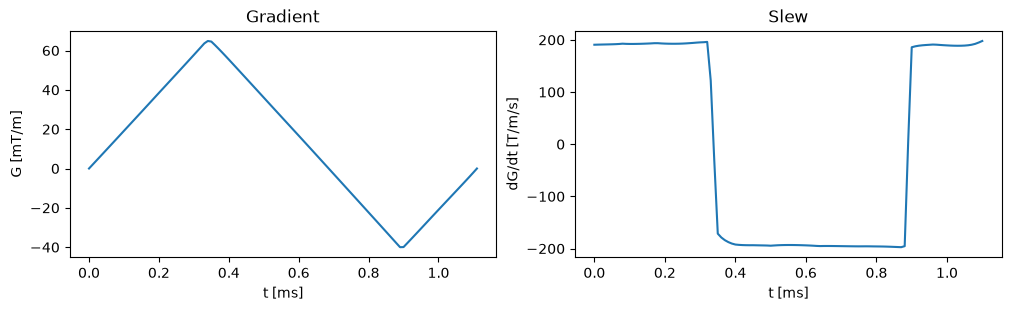

In [3]:
g = result.X
t_ms = np.arange(g.size) * gparams.dt * 1e3

fig, axs = plt.subplots(1, 2, figsize=(10, 3), layout='constrained')
axs[0].plot(t_ms, g * 1e3)
axs[0].set(xlabel='t [ms]', ylabel='G [mT/m]', title='Gradient')
axs[1].plot(t_ms[:-1], np.diff(g) / gparams.dt)
axs[1].set(xlabel='t [ms]', ylabel='dG/dt [T/m/s]', title='Slew')
plt.show()

## Check the moments

Moments are sums over the samples, with t measured from the first sample:

In [4]:
t = np.arange(g.size) * gparams.dt
M0 = np.sum(g) * gparams.dt * 1e6        # T*s/m -> mT*ms/m
M1 = np.sum(g * t) * gparams.dt * 1e9    # T*s^2/m -> mT*ms^2/m
print(f'M0 = {M0:.6f} mT*ms/m,  M1 = {M1:.1e} mT*ms^2/m')

M0 = 14.000001 mT*ms/m,  M1 = -5.3e-07 mT*ms^2/m


By default each moment only has to be within a small tolerance (1e-6 mT·ms/m for M0).
`add_moment(..., project=True)` enforces it exactly and is usually faster; see
[Flow encoding](moments/flow_encoding.ipynb).

## Next steps

- [Flow encoding](moments/flow_encoding.ipynb): exact moments, and finding the shortest waveform
- [Fixed gradient values](moments/nonzero_ends.ipynb): nonzero end values and fixed samples
- [Regularization](objective_functions/regularizations.ipynb): choosing among feasible waveforms
- [PNS](hardware/pns.ipynb) and [multiple axes](hardware/multi_axis.ipynb): hardware limits
- [Solver control](solvers/solver_control.ipynb): settings, convergence plots and warm starts
- [Diffusion encoding](diffusion/diffusion.ipynb), [minimum TE](diffusion/diffusion_te.ipynb) and the
  [low-level diffusion API](diffusion/diffusion_constraint.ipynb)